# 11 · Figures of the Results section

## 0. Configuration

In [ ]:
QUICK = False                         
SEEDS = [0] if QUICK else [0, 1, 2]
K_FOLDS = 5
EXAMPLE_SEED = 0                      
N_EXAMPLES = (2, 2)                   

CFG = dict(ct_eps=0.0, alphas=(0.05, 0.10), ltt_delta=0.10, min_pos=5, shape_dup_thr=5)
PLUG = ["FT", "KD", "FD", "WiSE", "OE", "MPT", "RA-LDL", "HCP", "RCLP", "CRCL", "Joint"]
COMPETITORS = ["MPT", "RA-LDL", "HCP", "RCLP", "CRCL"]
OURS = "OE+CURE10"
S2_METHODS = ["New", "New-FD"]
import numpy as _np; GRID = _np.linspace(-8, 8, 801)

## 1. Setup, style and helpers

In [ ]:
import json, sys, time, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from scipy import stats
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cv, crc, frontier, certify

OUT = config.OUTPUT_DIR
CACHE, RES = OUT / "cache", OUT / "results"
q = "_quick" if QUICK else ""
CV04, RAW, RAW8, RAW9, RAW10, S2DIR = (RES / f"cv{q}", RES / f"cv07{q}", RES / f"cv08{q}", RES / f"cv09{q}",
                                       RES / f"cv10{q}", RES / f"s2_07{q}")
SUM10, SUM08 = RES / f"main10_summary{q}.json", RES / f"main08_summary{q}.json"
FIG = config.FIGURE_DIR / ("article_quick" if QUICK else "article")
(FIG / "data").mkdir(parents=True, exist_ok=True)
need = [CV04 / "folds.csv", SUM10, SUM08] + [RAW / f"legacy__s{s}.npz" for s in SEEDS] + [S2DIR / f"legacy__s{s}.npz" for s in SEEDS]
miss = [p for p in need if not p.exists()]
assert not miss, f"Run notebooks 07 to 10 first: {miss[0]} not found"
J10, J08 = json.loads(SUM10.read_text()), json.loads(SUM08.read_text())
print("summaries loaded:", J10["notebook"], J10["verdict"], "|", J08["notebook"], J08["verdict"])


mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7.5, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.3, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "lines.linewidth": 1.0, "lines.solid_capstyle": "round",
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.default": "regular", "figure.dpi": 150, "savefig.dpi": 600, "axes.titlelocation": "left",
})
COL1, COL2 = 3.5, 7.16
# Okabe-Ito; colour follows the method in every figure
CURE_C = "#0072B2"                                           # CURE (our method) in every figure
COL = {"OE": "#3B4450", "HCP": "#E69F00", "RCLP": "#56B4E9", "CRCL": "#009E73", "MPT": "#CC79A7", "RA-LDL": "#D55E00"}
GREY, GREY_D, INK = "#A3A9B0", "#6E7781", "#1A1A1A"
BAD, FA_C, N_C = "#D55E00", "#E69F00", "#CC79A7"              # limit line / false alarm / counts
KEPT_C, MISS_C = "#009E73", "#D55E00"
NICE = {"WiSE": "WiSE-FT", "Joint": "Joint retraining", "Select": "Per-class selection", "Legacy-recal": "Legacy, recalibrated"}
XL = "New false alarms relative to the legacy model,\nNFR$^{-}$ (% of negative labels)"
YL = "Missed-disease flips relative to the legacy\nmodel, NFR$^{+}$ (% of positive labels)"
nice = lambda m: NICE.get(m, m)
mcol = lambda m: COL.get(m, GREY_D)


def save(fig, name, data=None):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(FIG / f"{name}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    if data is not None:
        data.to_csv(FIG / "data" / f"{name}.csv", index=False)
    print("saved", FIG / f"{name}.pdf")


def dotted_legend(ax, **kw):
    leg = ax.legend(frameon=True, fancybox=False, borderpad=0.4, handlelength=1.6, **kw)
    fr = leg.get_frame()
    fr.set_linestyle((0, (1, 1.5))); fr.set_edgecolor("#8C959F"); fr.set_linewidth(0.6); fr.set_facecolor("white"); fr.set_alpha(1)
    return leg


def color_ticks(labels, methods):
    """Colour each tick label with the colour of its method."""
    for t, m in zip(labels, methods):
        t.set_color(CURE_C if m == "CURE" else mcol(m))


def panel_tag(ax, s, x=-0.16, y=1.04):
    ax.text(x, y, f"({s})", transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")


def repel(ys, min_gap):
    """Spread label positions (sorted input order kept) so neighbours are at least min_gap apart."""
    ys = np.asarray(ys, float)
    o = np.argsort(ys)
    out = ys[o].copy()
    for _ in range(200):
        moved = False
        for i in range(1, len(out)):
            d = out[i] - out[i - 1]
            if d < min_gap:
                shift = (min_gap - d) / 2
                out[i - 1] -= shift; out[i] += shift; moved = True
        if not moved:
            break
    res = np.empty_like(out)
    res[o] = out
    return res


def m10(name):
    """Seed means of one row of the main table (notebook 10)."""
    r = J10["means"][name]
    return {"mAPsh": r["mAPsh"], "mAP": r["mAP"], "NFR+": r["NFR+"][0], "NFR+sd": r["NFR+"][1],
            "NFR-": r["NFR-"][0], "NFR-sd": r["NFR-"][1], "risk": r["risk"]}

summaries loaded: 10_cure_2025_baselines CONFIRMED | 08_confirm_and_main_tables CONFIRMED-FULL


## 2. Manifests, label space and labels of the pooled RFMiD 2.0 set (no images are loaded)

In [ ]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                       
new2 = space["new"]                                     
UNION = classes1 + new2                                
N_OLD = len(classes1)
shared_map = space["shared_map"]                       
SH = [UNION.index(c) for c in shared_map]                
RT = [UNION.index(c) for c in space["retired"]]         
NW = list(range(N_OLD, len(UNION)))                    
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


In [5]:
folds_df = pd.read_csv(CV04 / "folds.csv", dtype={"ID": str})
man2_all = pd.concat([pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS], ignore_index=True)
pool = folds_df.merge(man2_all, on=["split", "ID"], how="left", validate="one_to_one")
folds, groups = pool["fold"].values, pool["group"].values

def label_arrays(man, dataset):
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

Yp, Mp = label_arrays(pool, "rfmid2")
Y1v, M1v = label_arrays(man1["val"], "rfmid1")
Y1t, M1t = label_arrays(man1["test"], "rfmid1")
HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}
fp1 = pd.read_csv(CACHE / "fingerprints_rfmid1.csv", dtype={"ID": str})
fp2 = pd.read_csv(CACHE / "fingerprints_rfmid2.csv", dtype={"ID": str})
v1val_fp = man1["val"][["split", "ID"]].merge(fp1, on=["split", "ID"], how="left")
pool_fp = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
dmin, _ = audit.hamming_min(v1val_fp["phash"], pool_fp["phash"])
KEEP1V = dmin > CFG["shape_dup_thr"]
print(f"pooled RFMiD 2.0: {len(pool)} images; anchoring set: {KEEP1V.sum()} of {len(KEEP1V)} RFMiD 1.0 validation images")

pooled RFMiD 2.0: 748 images; anchoring set: 631 of 640 RFMiD 1.0 validation images


## 3. Rebuild the main-setting predictions with CURE

In [6]:
def raw_file(model, seed, fold):
    return RAW / f"{model}__s{seed}__f{fold}.npz"

def load_raw(model, seed, fold):
    if model == "FD":
        return np.load(RAW8 / f"FD__s{seed}__f{fold}.npz")
    if model in ("FT", "WiSE", "OE"):
        return np.load(raw_file(model, seed, fold))
    if model in ("HCP", "RCLP", "CRCL"):
        return np.load(RAW10 / f"{model}__s{seed}__f{fold}.npz")
    return np.load(RAW9 / f"{model}__s{seed}__f{fold}.npz")

def per_class_miss(VAR, LEG, names, Y, M, cls_idx, min_caught=5):
    rows = []
    for j, c in enumerate(cls_idx):
        rec = {"class": UNION[c]}
        for n in names:
            miss = tot = 0
            for s in SEEDS:
                L, T = VAR[(n, s)]
                Lo, to = LEG[s]
                caught = crc.legacy_caught(Lo, to, Y, M, cls_idx)[:, j]
                pred = L[:, c] >= cure.logit(T[:, c])
                miss += int((caught & ~pred).sum()); tot += int(caught.sum())
            rec["n_caught"] = tot / len(SEEDS)
            rec[n] = 100 * miss / tot if tot else np.nan
        rows.append(rec)
    df = pd.DataFrame(rows)
    return df[df["n_caught"] >= min_caught].sort_values("n_caught", ascending=False).reset_index(drop=True)

In [7]:
VAR, INFO, LEG = {}, [], {}
for seed in SEEDS:
    z = np.load(RAW / f"legacy__s{seed}.npz")
    L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
    LEG[seed] = (L_old, thr_old)
    fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
    caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
    VAR[("Legacy", seed)] = (L_old, np.broadcast_to(thr_old, L_old.shape).copy())
    acc = {}
    for k in range(K_FOLDS):
        te = np.where(folds == k)[0]
        va = np.where(folds == (k + 1) % K_FOLDS)[0]
        Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
        acc.setdefault("Legacy-recal", []).append((te, L_old[te], cv.plain_thresholds(lo_va, Yv, Mv, fallback)))
        ft = load_raw("FT", seed, k)
        Ls_va, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lva"], lo_va, SH, RT)
        Ls_te, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lte"], L_old[te], SH, RT)
        acc.setdefault("Select", []).append((te, Ls_te, cv.plain_thresholds(Ls_va, Yv, Mv, fallback)))
        for m in PLUG:
            try:
                r = load_raw(m, seed, k)
            except FileNotFoundError:
                continue
            Lva, Lte, L1v = r["Lva"], r["Lte"], r["L1v"]
            plain = cv.plain_thresholds(Lva, Yv, Mv, fallback)
            s = certify.fit_shape("ct", L1v[KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, None, CFG["ct_eps"])
            base = plain.copy()
            base[SH] = s[SH]
            caught_v = crc.legacy_caught(lo_va, thr_old, Yv, Mv, SH)
            acc.setdefault(m, []).append((te, Lte, plain))
            for a, tag, meth in [(0.10, "10", "CRC"), (0.05, "5", "CRC"), (0.10, "-LTT10", "LTT")]:
                if meth == "CRC":
                    lam, n_cal, ok = crc.calibrate(Lva, base, caught_v, SH, a, GRID)
                else:
                    lam, n_cal, ok = certify.ltt_calibrate(Lva, base, caught_v, SH, a, CFG["ltt_delta"], GRID)
                t = crc.shift_thresholds(base, SH, lam)
                name = f"{m}+CURE{tag}"
                acc.setdefault(name, []).append((te, Lte, t))
                risk = crc.image_losses(Lte, t, caught_all[te], SH)
                INFO.append({"variant": name, "seed": seed, "fold": k, "alpha": a, "method": meth, "lam": lam, "n_cal": n_cal,
                             "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
    for name, parts in acc.items():
        if len(parts) != K_FOLDS:
            print(f"  skipped {name} (seed {seed}): only {len(parts)} of {K_FOLDS} folds available")
            continue
        L = np.zeros((len(pool), len(UNION)), np.float32)
        T = np.zeros_like(L)
        for te, Lte, t in parts:
            L[te], T[te] = Lte, t[None, :]
        VAR[(name, seed)] = (L, T)
info = pd.DataFrame(INFO)
NAMES = [n for n in ["Legacy", "Legacy-recal", "Select"] + [f"{m}{s}" for m in PLUG for s in ("", "+CURE10", "+CURE5", "+CURE-LTT10")]
         if all((n, s) in VAR for s in SEEDS)]
print(f"{len(NAMES)} rows:", NAMES)

47 rows: ['Legacy', 'Legacy-recal', 'Select', 'FT', 'FT+CURE10', 'FT+CURE5', 'FT+CURE-LTT10', 'KD', 'KD+CURE10', 'KD+CURE5', 'KD+CURE-LTT10', 'FD', 'FD+CURE10', 'FD+CURE5', 'FD+CURE-LTT10', 'WiSE', 'WiSE+CURE10', 'WiSE+CURE5', 'WiSE+CURE-LTT10', 'OE', 'OE+CURE10', 'OE+CURE5', 'OE+CURE-LTT10', 'MPT', 'MPT+CURE10', 'MPT+CURE5', 'MPT+CURE-LTT10', 'RA-LDL', 'RA-LDL+CURE10', 'RA-LDL+CURE5', 'RA-LDL+CURE-LTT10', 'HCP', 'HCP+CURE10', 'HCP+CURE5', 'HCP+CURE-LTT10', 'RCLP', 'RCLP+CURE10', 'RCLP+CURE5', 'RCLP+CURE-LTT10', 'CRCL', 'CRCL+CURE10', 'CRCL+CURE5', 'CRCL+CURE-LTT10', 'Joint', 'Joint+CURE10', 'Joint+CURE5', 'Joint+CURE-LTT10']


In [8]:
def seed_points(VARd, LEGd, names, Y, M, idx):
    return {(n, s): frontier.point(frontier.flip_sets(*VARd[(n, s)], LEGd[s][0], LEGd[s][1], Y, M, idx))
            for n in names for s in SEEDS}

check = [n for n in NAMES if n in J10["means"] and n != "Legacy"]
P1 = seed_points(VAR, LEG, check, Yp, Mp, SH)
dev = []
for n in check:
    x = np.mean([P1[(n, s)][0] for s in SEEDS]); y = np.mean([P1[(n, s)][1] for s in SEEDS])
    dev.append((n, abs(x - J10["means"][n]["NFR-"][0]), abs(y - J10["means"][n]["NFR+"][0])))
dev = pd.DataFrame(dev, columns=["variant", "|dNFR-|", "|dNFR+|"])
worst = dev[["|dNFR-|", "|dNFR+|"]].max().max()
print(f"largest deviation from main10_summary.json: {worst:.3f} points over {len(dev)} rows")
assert worst < 0.02, "rebuilt predictions differ from notebook 10; rerun notebook 10 or check QUICK"

largest deviation from main10_summary.json: 0.005 points over 46 rows


## 4. Rebuild the second-setting predictions

In [9]:
TAGS = [int(round(100 * a)) for a in CFG["alphas"]]
def s2_file(model, seed):
    return S2DIR / f"{model}__s{seed}.npz"
VAR2, INFO2, LEG2 = {}, [], {}
if True:
    Y1t45, M1t45 = Y1t[:, :N_OLD], M1t[:, :N_OLD]
    Y1v45, M1v45 = Y1v[:, :N_OLD], M1v[:, :N_OLD]
    n_te = len(Y1t45)
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        LEG2[seed] = (Lo_t, thr_o)
        VAR2[("Legacy", seed)] = (Lo_t, np.broadcast_to(thr_o, Lo_t.shape).copy())
        raw = {m: np.load(s2_file(m, seed)) for m in S2_METHODS}
        logits = {m: (raw[m]["Lva"], raw[m]["Lte"]) for m in S2_METHODS}
        logits["OE"] = tuple(cure.output_ensemble(l, lo, N_OLD) for l, lo in zip(logits["New"], (Lo_v, Lo_t)))
        H = crc.split_halves(np.arange(n_te), 7000 + seed)              # same halves as notebook 07
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        for m, (Lv, Lt) in logits.items():
            fit = lambda kind: certify.fit_shape(kind, Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, None, CFG["ct_eps"])
            ct, un, leg = fit("ct"), fit("uniform"), thr_o.copy()
            full = lambda t: np.broadcast_to(t, Lt.shape).copy()
            T = {m: full(un), f"{m}+CT": full(ct), f"{m}+LEG": full(leg)}
            for a, tag in zip(CFG["alphas"], TAGS):
                plan = [("CRC", ct, "CRC"), ("CRCu", un, "CRC"), ("CRCleg", leg, "CRC"), ("LTT", ct, "LTT"), ("LTTu", un, "LTT")]
                for short, base, meth in plan:
                    name = f"{m}+{short}{tag}"
                    T[name] = np.zeros_like(Lt)
                    for h in (0, 1):
                        ev, cal = H[h], H[1 - h]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lt[cal], base, caught_t[cal], OLD, a, CFG["ltt_delta"], GRID)
                        t = crc.shift_thresholds(base, OLD, lam)
                        T[name][ev] = t[None, :]
                        risk = crc.image_losses(Lt[ev], t, caught_t[ev], OLD)
                        INFO2.append({"variant": name, "seed": seed, "half": h, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
            for name, t in T.items():
                VAR2[(name, seed)] = (Lt, t)
    info2 = pd.DataFrame(INFO2)
    NAMES2 = sorted({n for n, _ in VAR2}, key=lambda n: (n != "Legacy", n.split("+")[0], n))
    print(f"scenario 2: {len(NAMES2)} variants")

scenario 2: 40 variants


In [10]:
check2 = [n for n in ["New", "New-FD", "OE", "OE+CRC10", "OE+CRC5", "OE+LTT10", "OE+LTT5"] if n in J08["s2"]["means"]]
P2s = seed_points(VAR2, LEG2, check2, Y1t45, M1t45, OLD)
worst2 = max(max(abs(np.mean([P2s[(n, s)][0] for s in SEEDS]) - J08["s2"]["means"][n]["NFR-"][0]),
                 abs(np.mean([P2s[(n, s)][1] for s in SEEDS]) - J08["s2"]["means"][n]["NFR+"][0])) for n in check2)
print(f"second setting: largest deviation from main08_summary.json: {worst2:.3f} points")
assert worst2 < 0.02, "rebuilt second-setting predictions differ from notebook 08"

second setting: largest deviation from main08_summary.json: 0.005 points


## 5. CURE traced across risk levels

In [11]:
ALPHA_GRID = np.round(np.arange(0.02, 0.3001, 0.01), 3)

def cure_curve_main(m="OE"):
    acc = {a: [] for a in ALPHA_GRID}
    for seed in SEEDS:
        z = np.load(RAW / f"legacy__s{seed}.npz")
        L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
        fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
        parts = {a: [] for a in ALPHA_GRID}
        for k in range(K_FOLDS):
            te = np.where(folds == k)[0]
            va = np.where(folds == (k + 1) % K_FOLDS)[0]
            Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
            r = load_raw(m, seed, k)
            plain = cv.plain_thresholds(r["Lva"], Yv, Mv, fallback)
            sh = certify.fit_shape("ct", r["L1v"][KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, None, CFG["ct_eps"])
            base = plain.copy(); base[SH] = sh[SH]
            caught_v = crc.legacy_caught(lo_va, thr_old, Yv, Mv, SH)
            for a in ALPHA_GRID:
                lam, _, _ = crc.calibrate(r["Lva"], base, caught_v, SH, a, GRID)
                parts[a].append((te, r["Lte"], crc.shift_thresholds(base, SH, lam)))
        for a in ALPHA_GRID:
            L = np.zeros((len(pool), len(UNION)), np.float32); T = np.zeros_like(L)
            for te, Lte, t in parts[a]:
                L[te], T[te] = Lte, t[None, :]
            acc[a].append(frontier.point(frontier.flip_sets(L, T, L_old, thr_old, Yp, Mp, SH)))
    return pd.DataFrame([{"alpha": a, "NFR-": np.mean([p[0] for p in acc[a]]), "NFR+": np.mean([p[1] for p in acc[a]])} for a in ALPHA_GRID])

def cure_curve_second():
    acc = {a: [] for a in ALPHA_GRID}
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        new = np.load(s2_file("New", seed))
        Lv, Lt = (cure.output_ensemble(l, lo, N_OLD) for l, lo in zip((new["Lva"], new["Lte"]), (Lo_v, Lo_t)))
        halves = crc.split_halves(np.arange(len(Y1t45)), 7000 + seed)
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        base = certify.fit_shape("ct", Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, None, CFG["ct_eps"])
        for a in ALPHA_GRID:
            T = np.zeros_like(Lt)
            for h in (0, 1):
                ev, cal = halves[h], halves[1 - h]
                lam, _, _ = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                T[ev] = crc.shift_thresholds(base, OLD, lam)[None, :]
            acc[a].append(frontier.point(frontier.flip_sets(Lt, T, Lo_t, thr_o, Y1t45, M1t45, OLD)))
    return pd.DataFrame([{"alpha": a, "NFR-": np.mean([p[0] for p in acc[a]]), "NFR+": np.mean([p[1] for p in acc[a]])} for a in ALPHA_GRID])

t0 = time.time()
CC1, CC2 = cure_curve_main("OE"), cure_curve_second()
print(f"certified curves: {time.time() - t0:.0f}s")
for df, ref, names in [(CC1, J10["means"], ("OE+CURE10", "OE+CURE5")), (CC2, J08["s2"]["means"], ("OE+CRC10", "OE+CRC5"))]:
    for a, n in zip((0.10, 0.05), names):
        r = df[np.isclose(df.alpha, a)].iloc[0]
        d = max(abs(r["NFR-"] - ref[n]["NFR-"][0]), abs(r["NFR+"] - ref[n]["NFR+"][0]))
        print(f"  {n}: deviation from the summary {d:.3f} points")
        assert d < 0.02, f"certified curve does not reproduce {n}"

certified curves: 14s
  OE+CURE10: deviation from the summary 0.005 points
  OE+CURE5: deviation from the summary 0.002 points
  OE+CRC10: deviation from the summary 0.004 points
  OE+CRC5: deviation from the summary 0.004 points


## Fig. 7 · Ablation of the certification step (Table II(a))

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig07_ablation.pdf


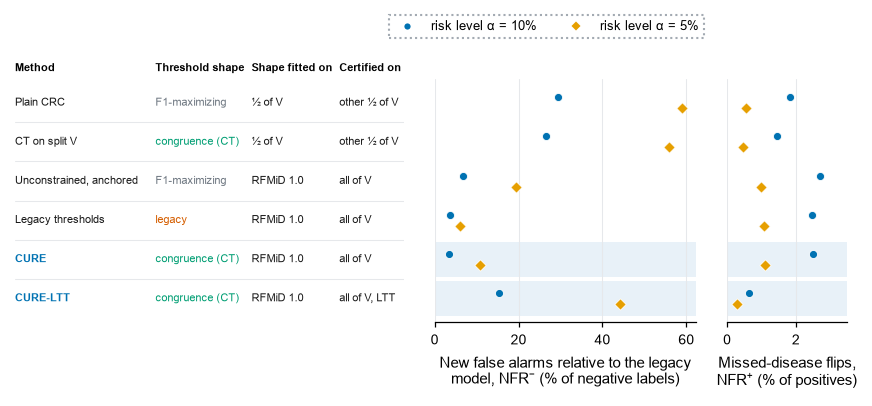

In [ ]:
S1 = J08["s1"]["means"]
ROWS7 = [  
    ("Plain CRC", "F1-maximizing", "½ of V", "other ½ of V", "OE+CRCu-A"),
    ("CT on split V", "congruence (CT)", "½ of V", "other ½ of V", "OE+CRC-A"),
    ("Unconstrained, anchored", "F1-maximizing", "RFMiD 1.0", "all of V", "OE+CRCu-L"),
    ("Legacy thresholds", "legacy", "RFMiD 1.0", "all of V", "OE+CRCleg"),
    ("CURE", "congruence (CT)", "RFMiD 1.0", "all of V", "OE+CRC-L"),
    ("CURE-LTT", "congruence (CT)", "RFMiD 1.0", "all of V, LTT", "OE+LTT-L"),
]
d7 = pd.DataFrame([{"method": r[0], "shape": r[1], "fitted_on": r[2], "certified_on": r[3], "alpha": a,
                    "NFR+": S1[f"{r[4]}{a}"]["NFR+"][0], "NFR-": S1[f"{r[4]}{a}"]["NFR-"][0]} for r in ROWS7 for a in (10, 5)])
A_STY = {10: dict(marker="o", color=CURE_C, label="risk level α = 10%"), 5: dict(marker="D", color=FA_C, label="risk level α = 5%")}
fig = plt.figure(figsize=(COL2, 2.1))
gs = fig.add_gridspec(1, 3, width_ratios=[2.75, 1.85, 0.85], wspace=0.12)
at, aA, aB = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
at.set_zorder(5); at.patch.set_alpha(0)
n = len(ROWS7)
yy = {r[0]: n - 1 - i for i, r in enumerate(ROWS7)}
at.set_xlim(0, 1); at.set_ylim(-0.6, n - 0.4); at.set_axis_off()
HEAD = ["Method", "Threshold shape", "Shape fitted on", "Certified on"]
cells = [[HEAD[j]] + [r[j] for r in ROWS7] for j in range(4)]
fig.canvas.draw(); rend = fig.canvas.get_renderer(); inv = at.transAxes.inverted()
widths = []
for col in cells:
    w = 0
    for t_ in col:
        tt = at.text(0, 0, t_, fontsize=6.2, fontweight="bold", transform=at.transAxes)
        bb = inv.transform(tt.get_window_extent(rend)); w = max(w, bb[1][0] - bb[0][0]); tt.remove()
    widths.append(w)
FS7 = 6.2 * min(1.0, 0.94 / sum(widths))            
widths = [w * FS7 / 6.2 for w in widths]
gap = max(0.02, (0.98 - sum(widths)) / 3)
cols_x = np.r_[0, np.cumsum(np.array(widths[:-1]) + gap)]
for cx, hd in zip(cols_x, HEAD):
    at.text(cx, n - 0.25, hd, fontsize=FS7, fontweight="bold", va="bottom", ha="left")
for r in ROWS7:
    y = yy[r[0]]
    c = CURE_C if r[0].startswith("CURE") else INK
    at.text(cols_x[0], y, r[0], fontsize=FS7, color=c, va="center", fontweight="bold" if c == CURE_C else "normal")
    at.text(cols_x[1], y, r[1], fontsize=FS7 - 0.2, va="center", color=KEPT_C if r[1].startswith("congruence") else (BAD if r[1] == "legacy" else GREY_D))
    at.text(cols_x[2], y, r[2], fontsize=FS7 - 0.2, va="center", color=INK)
    at.text(cols_x[3], y, r[3], fontsize=FS7 - 0.2, va="center", color=INK)
for y in yy.values():
    if y < n - 1:
        at.axhline(y + 0.5, color="#E6E8EB", lw=0.5)
for ax, col in [(aA, "NFR-"), (aB, "NFR+")]:
    for a in (10, 5):
        s_ = d7[d7.alpha == a]
        off = 0.14 if a == 10 else -0.14
        ax.scatter(s_[col], [yy[m] + off for m in s_.method], s=15, edgecolor="white", lw=0.4, zorder=3,
                   marker=A_STY[a]["marker"], color=A_STY[a]["color"], label=A_STY[a]["label"] if ax is aA else None)
    for m, y in yy.items():
        if m.startswith("CURE"):
            ax.axhspan(y - 0.45, y + 0.45, color="#E8F1F8", zorder=0, lw=0)
    ax.set_ylim(-0.6, n - 0.4); ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
aA.set_xlim(0, d7["NFR-"].max() * 1.06); aB.set_xlim(0, d7["NFR+"].max() * 1.3)
aA.set_xlabel("New false alarms relative to the legacy\nmodel, NFR$^{-}$ (% of negative labels)")
aB.set_xlabel("Missed-disease flips,\nNFR$^{+}$ (% of positives)")
leg = fig.legend(handles=[Line2D([], [], ls="", ms=4, mec="white", **{k: v for k, v in A_STY[a].items() if k != "color"},
                                 mfc=A_STY[a]["color"]) for a in (10, 5)],
                 loc="lower center", bbox_to_anchor=(0.62, 0.99), ncol=2, frameon=True, fancybox=False)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F")
save(fig, "fig07_ablation", d7)
plt.show()

## Fig. 8 · Threshold-sweep curves, threshold-tuning frontier and the certified curve of CURE

gap of CURE on OE (alpha = 10%) to the threshold-tuning frontier: -7.73 (95% CI -8.86 to -6.34)
saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig08_frontier.pdf


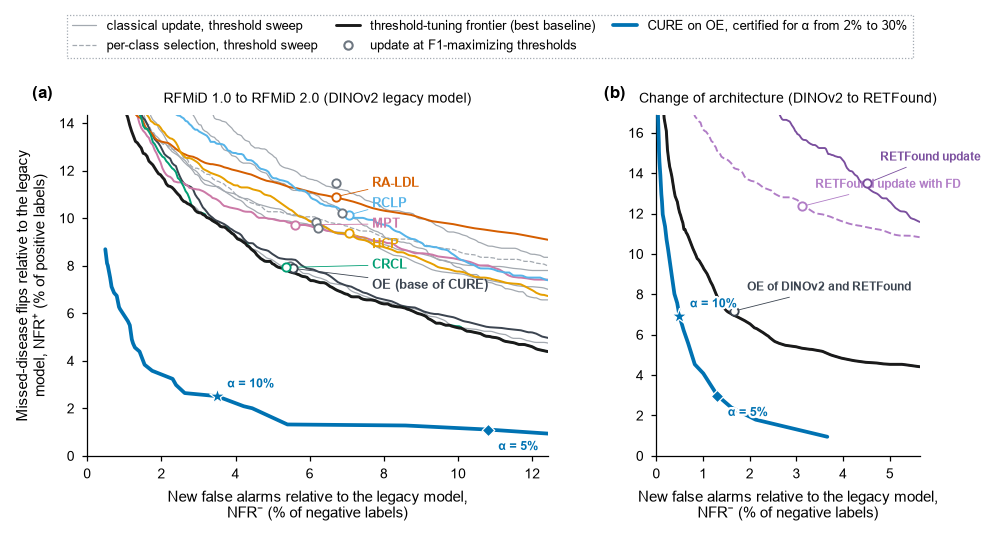

In [13]:
def seed_curve(FSd, m, xs):
    cs = [frontier.curve(FSd[(m, s)], GRID) for s in SEEDS]
    return np.mean([[frontier.frontier_at(*cc, v) for v in xs] for cc in cs], axis=0)

CURVES = [m for m in PLUG + ["Select"] if m in NAMES]
FS = {(m, s): frontier.flip_sets(*VAR[(m, s)], LEG[s][0], LEG[s][1], Yp, Mp, SH) for m in CURVES for s in SEEDS}
pts = {m: m10(m) for m in PLUG}
xmax = 1.15 * max([p["NFR-"] for p in pts.values()] + [m10("OE+CURE5")["NFR-"], m10(OURS)["NFR-"]])
xs = np.linspace(0, xmax, 240)
curv = {m: seed_curve(FS, m, xs) for m in CURVES}
env = np.min(np.vstack(list(curv.values())), axis=0)

CURVES2 = ["New", "New-FD", "OE"]
FS2 = {(m, s): frontier.flip_sets(*VAR2[(m, s)], LEG2[s][0], LEG2[s][1], Y1t45, M1t45, OLD) for m in CURVES2 for s in SEEDS}
S2 = J08["s2"]["means"]
xmax2 = 1.25 * max([S2[m]["NFR-"][0] for m in CURVES2 + ["OE+CRC10", "OE+CRC5"]])
xs2 = np.linspace(0, xmax2, 240)
curv2 = {m: seed_curve(FS2, m, xs2) for m in CURVES2}
env2 = np.min(np.vstack(list(curv2.values())), axis=0)

def cure_line(ax, cc, star, diamond):
    c = cc.sort_values("alpha", ascending=False)
    ax.plot(c["NFR-"], c["NFR+"], color=CURE_C, lw=1.8, zorder=6, solid_capstyle="round")
    for (a, mk, sz) in [(0.10, "*", 60), (0.05, "D", 18)]:
        r = cc[np.isclose(cc.alpha, a)].iloc[0]
        ax.scatter(r["NFR-"], r["NFR+"], marker=mk, s=sz, color=CURE_C, edgecolor="white", lw=0.6, zorder=7)
        t_ = ax.annotate(f"α = {int(round(100 * a))}%", (r["NFR-"], r["NFR+"]), xytext=(5, 6 if a == 0.10 else -8),
                         textcoords="offset points", fontsize=6.0, color=CURE_C, fontweight="bold", va="center", zorder=8)
        t_.set_path_effects([pe.Stroke(linewidth=2.2, foreground="white"), pe.Normal()])

fig, (ax, bx) = plt.subplots(1, 2, figsize=(COL2, 2.95), gridspec_kw={"width_ratios": [1.75, 1], "wspace": 0.3})
for m in CURVES:
    col, lw, z = (mcol(m), 0.95, 3) if m in COL else (GREY, 0.6, 2)
    ax.plot(xs, curv[m], color=col, lw=lw, zorder=z, ls="--" if m == "Select" else "-")
ax.plot(xs, env, color=INK, lw=1.4, zorder=4)
for m in PLUG:
    p = pts[m]
    col = mcol(m) if m in COL else GREY_D
    ax.scatter(p["NFR-"], p["NFR+"], s=16, facecolor="white", edgecolor=col, lw=0.9, zorder=5)
cure_line(ax, CC1, "OE+CURE10", "OE+CURE5")
lab_m = [m for m in PLUG if m in COL]
yr = max(max(p["NFR+"] for p in pts.values()), 1.0)
ly = repel([pts[m]["NFR+"] for m in lab_m], 0.075 * yr)
lx = max(pts[m]["NFR-"] for m in lab_m) + 0.05 * xmax
for m, yl in zip(lab_m, ly):
    ax.annotate(nice(m) + (" (base of CURE)" if m == "OE" else ""), (pts[m]["NFR-"], pts[m]["NFR+"]), xytext=(lx, yl),
                fontsize=6.0, color=mcol(m), va="center", fontweight="bold",
                arrowprops=dict(arrowstyle="-", lw=0.4, color=mcol(m), shrinkA=0, shrinkB=2))
g = J10["gap"][OURS]
print(f"gap of CURE on OE (alpha = 10%) to the threshold-tuning frontier: {g[0]:.2f} (95% CI {g[1]:.2f} to {g[2]:.2f})")
h = [Line2D([], [], color=GREY, lw=0.6, label="classical update, threshold sweep"),
     Line2D([], [], color=GREY, lw=0.6, ls="--", label="per-class selection, threshold sweep"),
     Line2D([], [], color=INK, lw=1.4, label="threshold-tuning frontier (best baseline)"),
     Line2D([], [], marker="o", ls="", mfc="white", mec=GREY_D, ms=4, label="update at F1-maximizing thresholds"),
     Line2D([], [], color=CURE_C, lw=1.8, label="CURE on OE, certified for α from 2% to 30%")]
leg = fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.995), ncol=3, frameon=True, fancybox=False,
                 handlelength=1.8, columnspacing=1.4)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F"); leg.get_frame().set_linewidth(0.6)
ax.set_xlim(0, xmax); ax.set_ylim(0, 1.25 * yr)
ax.set_xlabel(XL); ax.set_ylabel(YL)
ax.set_title("RFMiD 1.0 to RFMiD 2.0 (DINOv2 legacy model)", loc="center", fontsize=6.8)
panel_tag(ax, "a", x=-0.12)

COL2S = {"New": "#7A4E9E", "New-FD": "#B07CC6", "OE": COL["OE"]}
NM2 = {"New": "RETFound update", "New-FD": "RETFound update with FD", "OE": "OE of DINOv2 and RETFound"}
for m in CURVES2:
    bx.plot(xs2, curv2[m], color=COL2S[m], lw=0.9, ls="--" if m == "New-FD" else "-")
    bx.scatter(S2[m]["NFR-"][0], S2[m]["NFR+"][0], s=16, facecolor="white", edgecolor=COL2S[m], lw=0.9, zorder=5)
bx.plot(xs2, env2, color=INK, lw=1.4, zorder=4)
cure_line(bx, CC2, "OE+CRC10", "OE+CRC5")
ytop2 = 1.25 * max(S2[m]["NFR+"][0] for m in CURVES2)
for m, yl in zip(CURVES2, repel([S2[m]["NFR+"][0] for m in CURVES2], 0.08 * ytop2)):
    bx.annotate(NM2[m], (S2[m]["NFR-"][0], S2[m]["NFR+"][0]), xytext=(S2[m]["NFR-"][0] + 0.05 * xmax2, yl + 0.07 * ytop2),
                fontsize=5.8, color=COL2S[m], va="center", fontweight="bold",
                arrowprops=dict(arrowstyle="-", lw=0.4, color=COL2S[m], shrinkA=0, shrinkB=2))
bx.set_xlim(0, xmax2); bx.set_ylim(0, ytop2)
bx.set_xlabel(XL)
bx.set_title("Change of architecture (DINOv2 to RETFound)", loc="center", fontsize=6.8)
panel_tag(bx, "b", x=-0.2)
d8 = pd.DataFrame({"NFR-": xs, **{f"curve_{m}": curv[m] for m in CURVES}, "frontier": env})
CC1.to_csv(FIG / "data" / "fig08_cure_curve_main.csv", index=False); CC2.to_csv(FIG / "data" / "fig08_cure_curve_second.csv", index=False)
save(fig, "fig08_frontier", d8)
plt.show()

## Fig. 9 · CURE added to each update

Pearson r = 0.843 (p = 0.0011); Spearman rho = 0.682 (p = 0.0208); n = 11
saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig09_plugin.pdf


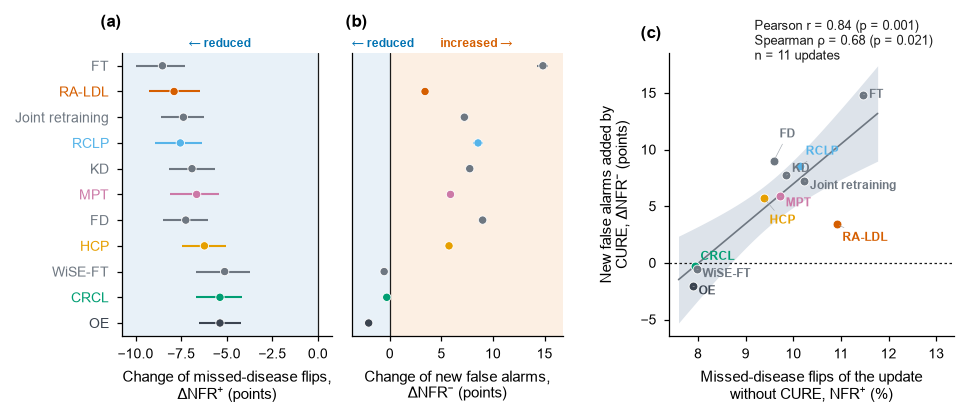

In [ ]:
SPACER = 0.32
order = sorted(PLUG, key=lambda m: m10(m)["NFR+"])
rows9 = []
for m in order:
    a = J10["d_NFR+"][f"PLUGIN {m}+CURE10 vs {m}"]; b = J10["d_NFR-"][f"PLUGIN {m}+CURE10 vs {m}"]
    rows9.append({"method": m, "update": nice(m), "base_NFR+": m10(m)["NFR+"], "dNFR+": a[0], "dNFR+_lo": a[1], "dNFR+_hi": a[2],
                  "dNFR-": b[0], "dNFR-_lo": b[1], "dNFR-_hi": b[2]})
d9 = pd.DataFrame(rows9)
fig = plt.figure(figsize=(COL2, 2.45))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, SPACER, 1.35], wspace=0.1)
a1 = fig.add_subplot(gs[0]); a2 = fig.add_subplot(gs[1], sharey=a1); a3 = fig.add_subplot(gs[3])
y = np.arange(len(d9))
cols = [mcol(m) if m in COL else GREY_D for m in d9["method"]]
for ax, k in [(a1, "dNFR+"), (a2, "dNFR-")]:
    lo_, hi_ = min(d9[f"{k}_lo"].min(), 0), max(d9[f"{k}_hi"].max(), 0)
    pad = 0.08 * (hi_ - lo_ + 1e-9)
    ax.axvspan(lo_ - pad, 0, color="#E8F1F8", zorder=0, lw=0)
    if hi_ > 0:
        ax.axvspan(0, hi_ + pad, color="#FCEFE3", zorder=0, lw=0)
    ax.hlines(y, d9[f"{k}_lo"], d9[f"{k}_hi"], color=cols, lw=1.0, zorder=2)
    ax.scatter(d9[k], y, s=16, color=cols, zorder=3, edgecolor="white", lw=0.4)
    ax.axvline(0, color=INK, lw=0.6)
    ax.set_xlim(lo_ - pad, hi_ + pad)
a1.set_yticks(y); a1.set_yticklabels(d9["update"]); color_ticks(a1.get_yticklabels(), d9["method"])
plt.setp(a2.get_yticklabels(), visible=False); a2.tick_params(axis="y", length=0)
a1.set_xlabel("Change of missed-disease flips,\nΔNFR$^{+}$ (points)"); a2.set_xlabel("Change of new false alarms,\nΔNFR$^{-}$ (points)")
import matplotlib.transforms as mtransforms
fig.canvas.draw()                                 
rend = fig.canvas.get_renderer()
for ax, k in [(a1, "dNFR+"), (a2, "dNFR-")]:
    x0_, x1_ = ax.get_xlim()
    tr = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)  
    regions = [("← reduced", x0_, 0.0, CURE_C)]
    if d9[k].max() > 0:
        regions.append(("increased →", 0.0, x1_, BAD))
    for lab, r0, r1, col in regions:
        t = ax.text((r0 + r1) / 2, 1.012, lab, transform=tr, fontsize=5.6, color=col,
                    va="bottom", ha="center", fontweight="bold", clip_on=False)
        bb = t.get_window_extent(rend).transformed(ax.transAxes.inverted())
        if bb.x0 < 0:                              
            t.set_transform(ax.transAxes); t.set_position((0.0, 1.012)); t.set_ha("left")
        elif bb.x1 > 1:
            t.set_transform(ax.transAxes); t.set_position((1.0, 1.012)); t.set_ha("right")
panel_tag(a1, "a", x=-0.1, y=1.08); panel_tag(a2, "b", x=-0.03, y=1.08)

xv, yv = d9["base_NFR+"].values, d9["dNFR-"].values
pr, pp = stats.pearsonr(xv, yv); sr, sp = stats.spearmanr(xv, yv)
lr = stats.linregress(xv, yv)
gx = np.linspace(xv.min() - 0.3, xv.max() + 0.3, 100)
nn = len(xv); tq = stats.t.ppf(0.975, nn - 2)
se = np.sqrt(np.sum((yv - (lr.intercept + lr.slope * xv)) ** 2) / (nn - 2)) * np.sqrt(1 / nn + (gx - xv.mean()) ** 2 / np.sum((xv - xv.mean()) ** 2))
a3.fill_between(gx, lr.intercept + lr.slope * gx - tq * se, lr.intercept + lr.slope * gx + tq * se, color="#DDE3EA", lw=0, zorder=1)
a3.plot(gx, lr.intercept + lr.slope * gx, color=GREY_D, lw=0.8, zorder=2)
a3.axhline(0, color=INK, lw=0.6, ls=(0, (2, 2)))
for (_, r), c in zip(d9.iterrows(), cols):
    a3.scatter(r["base_NFR+"], r["dNFR-"], s=18, color=c, edgecolor="white", lw=0.4, zorder=3)
lys = repel(d9["dNFR-"].values, 0.09 * (yv.max() - yv.min() + 1e-9))
for (_, r), yl, c in zip(d9.iterrows(), lys, cols):
    a3.annotate(r["update"], (r["base_NFR+"], r["dNFR-"]), xytext=(r["base_NFR+"] + 0.12, yl), fontsize=5.8, va="center",
                color=c, fontweight="bold", arrowprops=dict(arrowstyle="-", lw=0.3, color=GREY, shrinkA=0, shrinkB=1.5))
a3.text(0.3, 1.12, f"Pearson r = {pr:.2f} (p = {pp:.3f})\nSpearman ρ = {sr:.2f} (p = {sp:.3f})\nn = {nn} updates", transform=a3.transAxes,
        va="top", fontsize=6.0, color=INK)
a3.set_xlabel("Missed-disease flips of the update\nwithout CURE, NFR$^{+}$ (%)"); a3.set_ylabel("New false alarms added by\nCURE, ΔNFR$^{-}$ (points)")
a3.set_xlim(gx.min() - 0.2, gx.max() + 1.6)
panel_tag(a3, "c", x=-0.1)
print(f"Pearson r = {pr:.3f} (p = {pp:.4f}); Spearman rho = {sr:.3f} (p = {sp:.4f}); n = {nn}")
save(fig, "fig09_plugin", d9)
plt.show()

## Fig. 10 · Validity of the certificates

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig10_validity.pdf


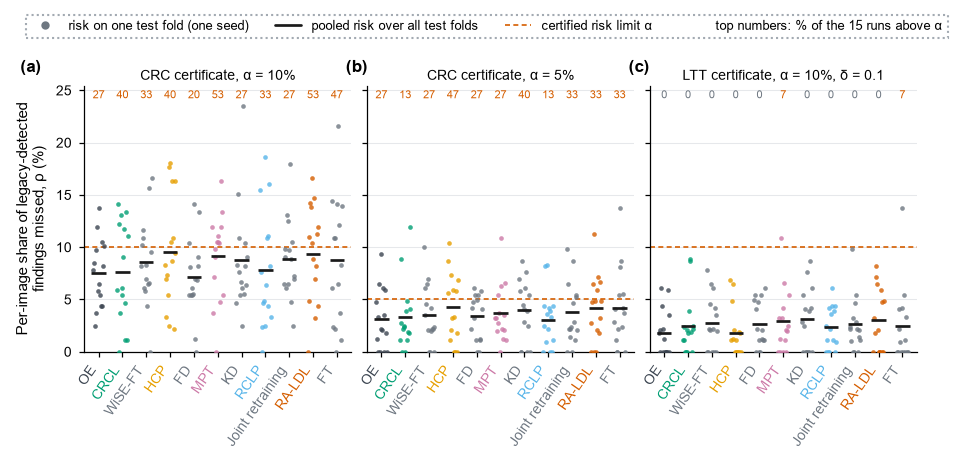

In [15]:
CERTS = [("CURE10", "CRC certificate, α = 10%", 10), ("CURE5", "CRC certificate, α = 5%", 5), ("CURE-LTT10", "LTT certificate, α = 10%, δ = 0.1", 10)]
v = info.copy()
v["base"] = v["variant"].str.split("+").str[0]
v["kind"] = v["variant"].str.split("+").str[1]
v["risk_%"] = 100 * v["test_risk"]
fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.3), sharey=True, gridspec_kw={"wspace": 0.06})
ymax = max(13.0, v["risk_%"].max() * 1.08)
rng = np.random.default_rng(0)
for ax, (kind, title, a) in zip(axs, CERTS):
    for i, m in enumerate(order):
        r = v[(v.base == m) & (v.kind == kind)]["risk_%"].values
        jit = np.linspace(-0.22, 0.22, len(r)) if len(r) > 1 else np.zeros(1)
        ax.scatter(i + rng.permutation(jit), r, s=5, color=mcol(m) if m in COL else GREY_D, alpha=0.8, lw=0, zorder=3)
        ax.hlines(J10["means"][f"{m}+{kind}"]["risk"], i - 0.3, i + 0.3, color=INK, lw=1.3, zorder=4)
        share = J10["validity"][f"{m}+{kind}"][1]
        ax.text(i, ymax * 0.985, f"{100 * share:.0f}", ha="center", va="top", fontsize=5.4, color=BAD if share > 0 else GREY_D)
    ax.axhline(a, color=BAD, lw=0.8, ls=(0, (3, 2)), zorder=2)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([nice(m) for m in order], rotation=55, ha="right")
    color_ticks(ax.get_xticklabels(), order)
    ax.set_title(title, loc="center", pad=3, fontsize=6.8); ax.set_ylim(0, ymax); ax.set_xlim(-0.6, len(order) - 0.4)
    ax.grid(axis="y", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
axs[0].set_ylabel("Per-image share of legacy-detected\nfindings missed, ρ (%)")
for ax, t_ in zip(axs, "abc"):
    panel_tag(ax, t_, x=-0.08 if t_ != "a" else -0.24)
h = [Line2D([], [], marker="o", ls="", color=GREY_D, ms=3, label="risk on one test fold (one seed)"),
     Line2D([], [], color=INK, lw=1.3, label="pooled risk over all test folds"),
     Line2D([], [], color=BAD, lw=0.8, ls=(0, (3, 2)), label="certified risk limit α"),
     Line2D([], [], ls="", label="top numbers: % of the 15 runs above α")]
leg = fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=True, fancybox=False)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F")
save(fig, "fig10_validity", v[["variant", "seed", "fold", "alpha", "method", "lam", "n_cal", "feasible", "risk_%"]])
plt.show()

## Fig. 11 · Missed findings per shared class

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig11_perclass.pdf


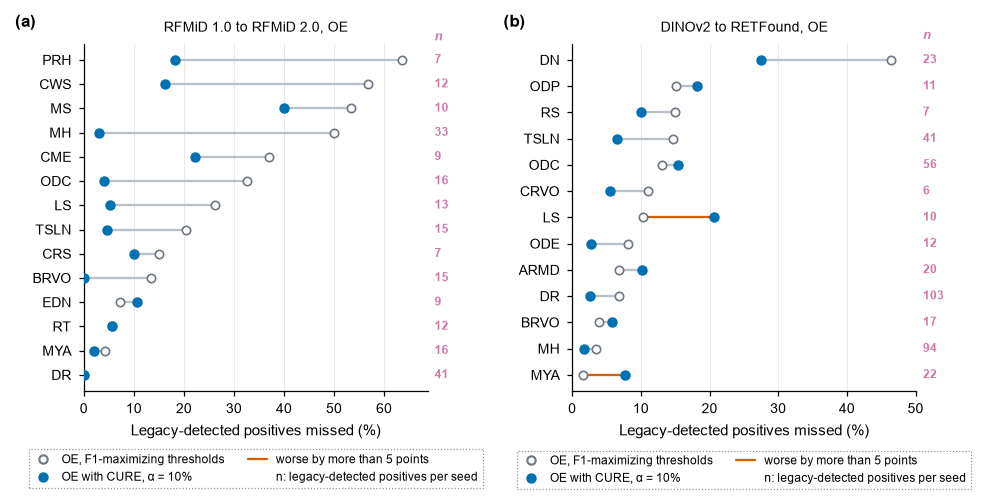

In [16]:
pc1 = per_class_miss(VAR, LEG, ["OE", OURS], Yp, Mp, SH)
pc2 = per_class_miss(VAR2, LEG2, ["OE", "OE+CRC10"], Y1t45, M1t45, OLD)
fig, axs = plt.subplots(1, 2, figsize=(COL2, max(2.4, 0.15 * max(len(pc1), len(pc2)) + 0.9)), gridspec_kw={"wspace": 0.42})
for ax, df, ours, title, t_ in [(axs[0], pc1, OURS, "RFMiD 1.0 to RFMiD 2.0, OE", "a"),
                               (axs[1], pc2, "OE+CRC10", "DINOv2 to RETFound, OE", "b")]:
    df = df.sort_values("OE").reset_index(drop=True)
    y = np.arange(len(df))
    for i, r in df.iterrows():
        worse = r[ours] - r["OE"] > 5
        ax.plot([r["OE"], r[ours]], [i, i], color=BAD if worse else "#B9C0C8", lw=1.1, zorder=1)
    ax.scatter(df["OE"], y, s=16, facecolor="white", edgecolor=GREY_D, lw=0.8, zorder=3)
    ax.scatter(df[ours], y, s=16, color=CURE_C, zorder=4)
    ax.set_yticks(y); ax.set_yticklabels(df["class"])
    for i, r in df.iterrows():
        ax.text(1.02, i, f"{r['n_caught']:.0f}", transform=ax.get_yaxis_transform(), fontsize=5.6, color=N_C, va="center", fontweight="bold")
    ax.text(1.02, len(df) - 0.3, "n", transform=ax.get_yaxis_transform(), fontsize=6.0, color=N_C, va="bottom", style="italic", fontweight="bold")
    ax.set_xlim(0, max(df[["OE", ours]].max().max() * 1.08, 10))
    ax.set_xlabel("Legacy-detected positives missed (%)"); ax.set_title(title, loc="center", fontsize=6.8)
    ax.grid(axis="x", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
    panel_tag(ax, t_, x=-0.2)
    h = [Line2D([], [], marker="o", ls="", mfc="white", mec=GREY_D, ms=4, label="OE, F1-maximizing thresholds"),
         Line2D([], [], marker="o", ls="", color=CURE_C, ms=4, label="OE with CURE, α = 10%"),
         Line2D([], [], color=BAD, lw=1.1, label="worse by more than 5 points"),
         Line2D([], [], ls="", label="n: legacy-detected positives per seed")]
    dotted_legend(ax, handles=h, loc="upper center", bbox_to_anchor=(0.5, -0.11 - 0.6 / max(len(df), 1)), ncol=2, fontsize=5.6)
pc_all = pd.concat([pc1.assign(setting="main"), pc2.rename(columns={"OE+CRC10": OURS}).assign(setting="second")])
save(fig, "fig11_perclass", pc_all)
plt.show()

candidates: 6 without and 36 with a new false alarm; showing 4
class abbreviations shown: ['AION', 'BRVO', 'CWS', 'DR', 'ERM', 'MH', 'ODE']
saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig12_examples.pdf


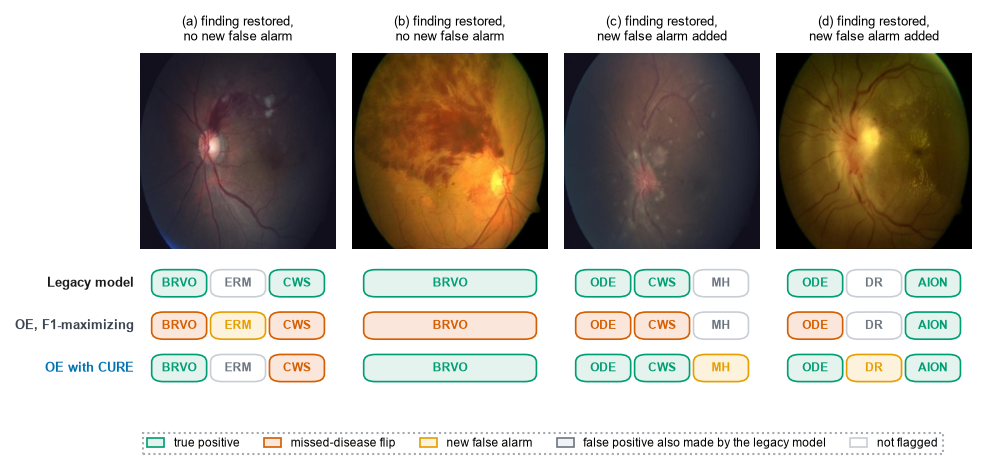

In [ ]:
s0 = EXAMPLE_SEED
Lo, to = LEG[s0]
Lb, Tb = VAR[("OE", s0)]
Lc, Tc = VAR[(OURS, s0)]
P_old = Lo[:, SH] >= cure.logit(to[SH])[None, :]
P_oe = Lb[:, SH] >= cure.logit(Tb[:, SH])
P_cu = Lc[:, SH] >= cure.logit(Tc[:, SH])
known = Mp[:, SH] > 0
pos, neg = known & (Yp[:, SH] == 1), known & (Yp[:, SH] == 0)
caught = pos & P_old
restored = caught & ~P_oe & P_cu
fa_cu = neg & ~P_old & P_cu
paths = [CACHE / "rfmid2" / f"{s}_{i}.jpg" for s, i in zip(pool["split"], pool["ID"])]
ok = np.array([p.exists() for p in paths])
cand_gain = [i for i in range(len(pool)) if ok[i] and restored[i].any() and not fa_cu[i].any()]
cand_trade = [i for i in range(len(pool)) if ok[i] and restored[i].any() and fa_cu[i].any()]
rank = lambda L_: sorted(L_, key=lambda i: (-int(caught[i].sum()), i))
chosen = [(i, "finding restored,\nno new false alarm") for i in rank(cand_gain)[:N_EXAMPLES[0]]] + \
         [(i, "finding restored,\nnew false alarm added") for i in rank(cand_trade)[:N_EXAMPLES[1]]]
print(f"candidates: {len(cand_gain)} without and {len(cand_trade)} with a new false alarm; showing {len(chosen)}")
assert chosen, "no example image found for this seed"

def state(i, j, P):
    if pos[i, j] and P[i, j]:
        return "tp"
    if pos[i, j] and P_old[i, j] and not P[i, j]:
        return "miss"
    if neg[i, j] and not P_old[i, j] and P[i, j]:
        return "fa"
    if neg[i, j] and P[i, j]:
        return "fp"
    return "off"
STY = {"tp": (KEPT_C, "#E4F3EE"), "miss": (MISS_C, "#FBE6DC"), "fa": (FA_C, "#FDF2DB"), "fp": (GREY_D, "#F2F3F5"), "off": ("#C9CED4", "white")}

ncol = len(chosen)
fig = plt.figure(figsize=(COL2, 2.95))
gs = fig.add_gridspec(2, ncol, height_ratios=[1.0, 0.62], hspace=0.05, wspace=0.08)
used = set()
rows_lab = [("Legacy model", P_old, INK), ("OE, F1-maximizing", P_oe, COL["OE"]), ("OE with CURE", P_cu, CURE_C)]
recs = []
for k, (i, kind) in enumerate(chosen):
    ax = fig.add_subplot(gs[0, k])
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.set_axis_off()
    ax.set_title(f"({chr(97 + k)}) {kind}", fontsize=6.0, loc="center")
    rest_j = [j for j in range(len(SH)) if restored[i, j]][:2]
    fa_j = [j for j in range(len(SH)) if fa_cu[i, j] or (neg[i, j] and P_oe[i, j] and not P_old[i, j])][:1]
    other = [j for j in range(len(SH)) if caught[i, j] and j not in rest_j]
    cls = (rest_j + fa_j + other)[:4]
    used.update(UNION[SH[j]] for j in cls)
    bx = fig.add_subplot(gs[1, k]); bx.set_xlim(0, 1); bx.set_ylim(0, 3); bx.set_axis_off()
    w = 0.9 / max(len(cls), 1)
    for r_, (lab, P, lc) in enumerate(rows_lab):
        yy = 2.5 - r_
        if k == 0:
            bx.text(-0.03, yy, lab, ha="right", va="center", fontsize=6.0, fontweight="bold", color=lc)
        for c_, j in enumerate(cls):
            st = state(i, j, P)
            ec, fc = STY[st]
            x0 = 0.05 + c_ * w
            bx.add_patch(FancyBboxPatch((x0 + 0.01, yy - 0.32), w - 0.02, 0.64, boxstyle="round,pad=0,rounding_size=0.06",
                                        fc=fc, ec=ec, lw=0.8, mutation_aspect=3))
            bx.text(x0 + w / 2, yy, UNION[SH[j]], ha="center", va="center", fontsize=5.6, color=ec if st != "off" else GREY_D,
                    fontweight="bold")
            recs.append({"panel": chr(97 + k), "pool_index": i, "ID": pool["ID"][i], "split": pool["split"][i],
                         "row": lab, "class": UNION[SH[j]], "state": st})
h = [FancyBboxPatch((0, 0), 1, 1, fc=STY[s][1], ec=STY[s][0], lw=0.8, label=l) for s, l in
     [("tp", "true positive"), ("miss", "missed-disease flip"), ("fa", "new false alarm"), ("fp", "false positive also made by the legacy model"),
      ("off", "not flagged")]]
leg = fig.legend(handles=h, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.05), frameon=True, fancybox=False, fontsize=5.8, handlelength=1.4)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F")
print("class abbreviations shown:", sorted(used))
save(fig, "fig12_examples", pd.DataFrame(recs))
plt.show()

## Fig. S1 · CURE against every baseline

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\figS1_forest.pdf


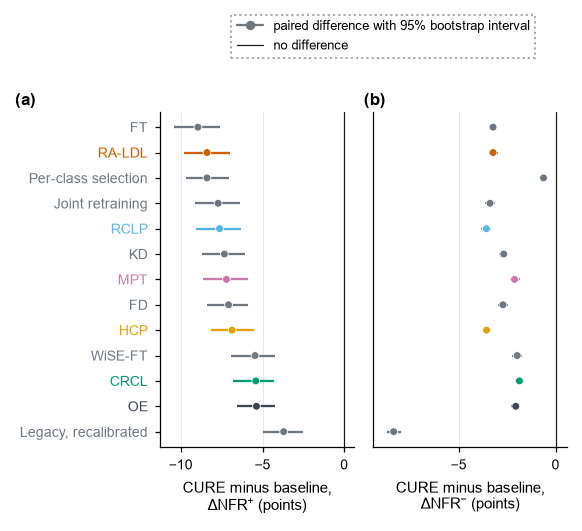

In [ ]:
BASE_S1 = ["Legacy-recal", "Joint", "FT", "KD", "FD", "WiSE", "OE", "Select", "HCP", "RCLP", "CRCL", "MPT", "RA-LDL"]
rs = []
for m in BASE_S1:
    a = J10["d_NFR+"][f"MAIN {OURS} vs {m}"]; b = J10["d_NFR-"][f"MAIN {OURS} vs {m}"]
    rs.append({"method": m, "baseline": nice(m), "dNFR+": a[0], "lo+": a[1], "hi+": a[2], "dNFR-": b[0], "lo-": b[1], "hi-": b[2]})
dS1 = pd.DataFrame(rs).sort_values("dNFR+", ascending=False).reset_index(drop=True)
ypos = np.arange(len(dS1))
cols = [mcol(m) if m in COL else GREY_D for m in dS1["method"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL1, 2.9), sharey=True, gridspec_kw={"wspace": 0.1})
for ax, k, lo, hi in [(a1, "dNFR+", "lo+", "hi+"), (a2, "dNFR-", "lo-", "hi-")]:
    ax.hlines(ypos, dS1[lo], dS1[hi], color=cols, lw=1.1)
    ax.scatter(dS1[k], ypos, s=14, color=cols, zorder=3, edgecolor="white", lw=0.4)
    ax.axvline(0, color=INK, lw=0.6); ax.grid(axis="x", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
    ax.set_xlim(min(dS1[lo].min() * 1.08, -0.5), 0.6)
a1.set_yticks(ypos); a1.set_yticklabels(dS1["baseline"]); color_ticks(a1.get_yticklabels(), dS1["method"])
a2.tick_params(axis="y", length=0)
a1.set_xlabel("CURE minus baseline,\nΔNFR$^{+}$ (points)"); a2.set_xlabel("CURE minus baseline,\nΔNFR$^{-}$ (points)")
h = [Line2D([], [], marker="o", color=GREY_D, ms=3.5, lw=1.1, label="paired difference with 95% bootstrap interval"),
     Line2D([], [], color=INK, lw=0.6, label="no difference")]
leg = fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.55, 0.99), ncol=1, frameon=True, fancybox=False)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F")
panel_tag(a1, "a", x=-0.75, y=1.01); panel_tag(a2, "b", x=-0.05, y=1.01)
save(fig, "figS2_forest", dS1)
plt.show()

## Fig. S2 · Accuracy and regression

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\figS2_accuracy_regression.pdf


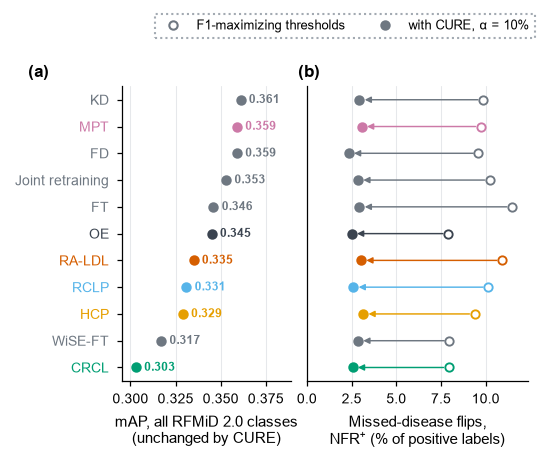

In [ ]:
dS2 = pd.DataFrame([{"update": nice(m), "method": m, "mAP": m10(m)["mAP"], "NFR+": m10(m)["NFR+"],
                     "NFR+_CURE": m10(f"{m}+CURE10")["NFR+"]} for m in PLUG]).sort_values("mAP").reset_index(drop=True)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(COL1, 2.55), sharey=True, gridspec_kw={"width_ratios": [1.15, 1.5], "wspace": 0.08})
y = np.arange(len(dS2))
for i, r in dS2.iterrows():
    c = mcol(r["method"]) if r["method"] in COL else GREY_D
    a1.scatter(r["mAP"], i, s=16, color=c, zorder=3)
    a1.annotate(f"{r['mAP']:.3f}", (r["mAP"], i), xytext=(4, 0), textcoords="offset points", fontsize=5.6, color=c,
                va="center", fontweight="bold")
    a2.annotate("", xy=(r["NFR+_CURE"], i), xytext=(r["NFR+"], i),
                arrowprops=dict(arrowstyle="-|>", lw=0.7, color=c, mutation_scale=6, shrinkA=2.5, shrinkB=2.5))
    a2.scatter(r["NFR+"], i, s=16, facecolor="white", edgecolor=c, lw=0.9, zorder=3)
    a2.scatter(r["NFR+_CURE"], i, s=16, color=c, zorder=3)
a1.set_yticks(y); a1.set_yticklabels(dS2["update"]); color_ticks(a1.get_yticklabels(), dS2["method"])
a2.tick_params(axis="y", length=0)
a1.set_xlabel("mAP, all RFMiD 2.0 classes\n(unchanged by CURE)"); a2.set_xlabel("Missed-disease flips,\nNFR$^{+}$ (% of positive labels)")
a2.set_xlim(0, dS2["NFR+"].max() * 1.08)
span = dS2["mAP"].max() - dS2["mAP"].min()
a1.set_xlim(dS2["mAP"].min() - 0.12 * span - 1e-3, dS2["mAP"].max() + 0.45 * span + 2e-3)
for ax in (a1, a2):
    ax.grid(axis="x", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
h = [Line2D([], [], marker="o", ls="", mfc="white", mec=GREY_D, ms=4, label="F1-maximizing thresholds"),
     Line2D([], [], marker="o", ls="", color=GREY_D, ms=4, label="with CURE, α = 10%")]
leg = fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.55, 0.99), ncol=2, frameon=True, fancybox=False)
leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F")
panel_tag(a1, "a", x=-0.55, y=1.02); panel_tag(a2, "b", x=-0.04, y=1.02)
save(fig, "figS3_accuracy_regression", dS2)
plt.show()

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\figS3_calibration_size.pdf


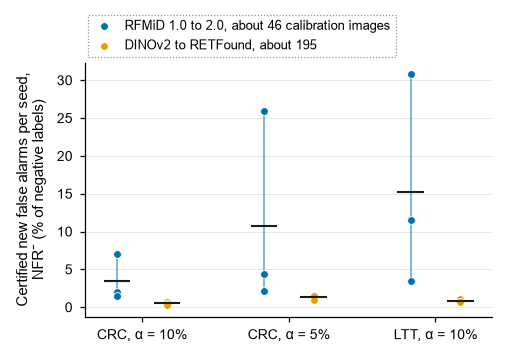

In [20]:
P1o = seed_points(VAR, LEG, ["OE+CURE10", "OE+CURE5", "OE+CURE-LTT10"], Yp, Mp, SH)
P2o = seed_points(VAR2, LEG2, ["OE+CRC10", "OE+CRC5", "OE+LTT10"], Y1t45, M1t45, OLD)
spec = [("CRC, α = 10%", "OE+CURE10", "OE+CRC10"), ("CRC, α = 5%", "OE+CURE5", "OE+CRC5"), ("LTT, α = 10%", "OE+CURE-LTT10", "OE+LTT10")]
SET = [("RFMiD 1.0 to 2.0, about 46 calibration images", CURE_C), ("DINOv2 to RETFound, about 195", FA_C)]
rows_s3 = []
for lab, n1, n2 in spec:
    for s in SEEDS:
        rows_s3.append({"certificate": lab, "setting": SET[0][0], "seed": s, "NFR-": P1o[(n1, s)][0]})
        rows_s3.append({"certificate": lab, "setting": SET[1][0], "seed": s, "NFR-": P2o[(n2, s)][0]})
dS3 = pd.DataFrame(rows_s3)
fig, ax = plt.subplots(figsize=(COL1, 2.2))
for i, (lab, _, _) in enumerate(spec):
    for k, (st, c) in enumerate(SET):
        vals = dS3[(dS3.certificate == lab) & (dS3.setting == st)]["NFR-"].values
        xx = i + (-0.17 if k == 0 else 0.17)
        ax.vlines(xx, vals.min(), vals.max(), color=c, lw=0.8, alpha=0.6)
        ax.scatter(np.full(len(vals), xx), vals, s=14, color=c, zorder=3, edgecolor="white", lw=0.4, label=st if i == 0 else None)
        ax.hlines(vals.mean(), xx - 0.09, xx + 0.09, color=INK, lw=1.0, zorder=4)
ax.set_xticks(range(len(spec))); ax.set_xticklabels([s[0] for s in spec])
ax.set_ylabel("Certified new false alarms per seed,\nNFR$^{-}$ (% of negative labels)")
ax.grid(axis="y", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
dotted_legend(ax, loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=1, borderaxespad=0.2)
save(fig, "figS3_calibration_size", dS3)
plt.show()